# Bundle-run prediction notebook for nnUNet v2

Use this notebook inside a copied `single_case_bundle_*` folder. It auto-detects the bundle directory from the notebook location or current working directory.

If auto-detection fails, set `USER_BUNDLE_DIR` manually.

In [6]:
from pathlib import Path
import json
import os
import re
import shutil
import subprocess
import importlib
import urllib.request

# =========================
# SETTINGS
# =========================
USER_BUNDLE_DIR = None  # oppure Path(r"C:\...\single_case_bundle")

DATASET_NAME = "Dataset100_lesion"
CONFIG = "3d_fullres"
TRAINER = "nnUNetTrainerBS4_CC_VOLAWARE"
CHECKPOINT_NAME = "checkpoint_best_global.pth"

CASE_ID = None
RUN_EVALUATION = True

# =========================
# HELPERS
# =========================
def is_bundle_dir(p: Path) -> bool:
    return (
        (p / "images").exists()
        and p.exists()
    )


def resolve_notebook_path():
    # In VS Code notebooks this global is the most reliable source.
    vsc_notebook_path = globals().get("__vsc_ipynb_file__")
    if vsc_notebook_path:
        p = Path(vsc_notebook_path).expanduser().resolve()
        if p.exists():
            return p

    kernel_id = None
    try:
        import ipykernel
        connection_file = ipykernel.get_connection_file()
        match = re.search(r"kernel-(.+).json", connection_file)
        if match:
            kernel_id = match.group(1)
    except Exception:
        kernel_id = None

    if kernel_id is None:
        return None

    servers = []
    try:
        from notebook import notebookapp
        servers = list(notebookapp.list_running_servers())
    except Exception:
        try:
            from jupyter_server.serverapp import list_running_servers
            servers = list(list_running_servers())
        except Exception:
            servers = []

    for server in servers:
        try:
            token = server.get("token", "")
            base_url = server.get("url", "")
            notebook_dir = Path(server.get("notebook_dir", "."))
            api_url = f"{base_url}api/sessions"
            if token:
                api_url += f"?token={token}"
            with urllib.request.urlopen(api_url) as response:
                sessions = json.loads(response.read().decode("utf-8"))
            for session in sessions:
                kernel = session.get("kernel", {})
                if kernel.get("id") == kernel_id:
                    return (notebook_dir / session["notebook"]["path"]).resolve()
        except Exception:
            continue

    return None


def resolve_bundle_dir(user_bundle_dir=None) -> Path:
    candidates = []

    if user_bundle_dir is not None:
        candidates.append(Path(user_bundle_dir))

    notebook_path = resolve_notebook_path()
    if notebook_path is not None:
        notebook_dir = notebook_path.parent.resolve()
        candidates += [
            notebook_dir,
            notebook_dir / "single_case_bundle",
        ]
        candidates += sorted(notebook_dir.glob("single_case_bundle*"))

    cwd = Path.cwd().resolve()
    candidates += [
        cwd,
        cwd / "single_case_bundle",
    ]
    candidates += sorted(cwd.glob("single_case_bundle*"))

    seen = set()
    for c in candidates:
        c = c.resolve()
        if str(c) in seen:
            continue
        seen.add(str(c))

        if is_bundle_dir(c):
            return c

    raise RuntimeError("Bundle not found. Set USER_BUNDLE_DIR manually.")


def run_live(cmd, env=None):
    print("\nRunning:")
    print(" ".join(map(str, cmd)))
    print()

    process = subprocess.Popen(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
        env=env,
    )

    for line in process.stdout:
        print(line, end="")

    returncode = process.wait()

    if returncode != 0:
        raise RuntimeError(f"Command failed with return code {returncode}")


# =========================
# RESOLVE BUNDLE
# =========================
BUNDLE_DIR = resolve_bundle_dir(USER_BUNDLE_DIR)

IMAGES_DIR = BUNDLE_DIR / "images"
LABELS_DIR = BUNDLE_DIR / "labels"
RESULTS_DIR = (BUNDLE_DIR / "../../template_folder/nnUNet_results").resolve()
CUSTOM_TRAINERS_DIR = (BUNDLE_DIR / "../../template_folder/custom_trainers").resolve()
METADATA_DIR = BUNDLE_DIR / "metadata"
#OUTPUT_DIR = BUNDLE_DIR / f"preds_{CONFIG}_{TRAINER}_ensemble"
OUTPUT_DIR = BUNDLE_DIR / f"preds_{CONFIG}_{TRAINER}_fold_all"

RUNTIME_DIR = BUNDLE_DIR / "_runtime"
NNUNET_RAW = RUNTIME_DIR / "nnUNet_raw"
NNUNET_PREPROCESSED = RUNTIME_DIR / "nnUNet_preprocessed"
NNUNET_RESULTS = RESULTS_DIR

print("Bundle directory:", BUNDLE_DIR)
if "/.Trashes/" in str(BUNDLE_DIR):
    print("WARNING: bundle path resolved inside Trash. Set USER_BUNDLE_DIR manually.")
print("Images:", IMAGES_DIR)
print("nnUNet_results:", RESULTS_DIR)
print("Custom trainers:", CUSTOM_TRAINERS_DIR)
print("Output:", OUTPUT_DIR)

# =========================
# BASIC CHECKS
# =========================
for p in [IMAGES_DIR, RESULTS_DIR, CUSTOM_TRAINERS_DIR]:
    if not p.exists():
        raise FileNotFoundError(p)

if shutil.which("nnUNetv2_predict") is None:
    raise RuntimeError("nnUNetv2_predict not found. Activate the nnUNet environment.")

# =========================
# INSTALL CUSTOM TRAINER
# =========================
import nnunetv2

src_trainer = CUSTOM_TRAINERS_DIR / f"{TRAINER}.py"

if not src_trainer.exists():
    raise FileNotFoundError(f"Missing custom trainer: {src_trainer}")

txt = src_trainer.read_text(errors="ignore")
if f"class {TRAINER}" not in txt:
    raise RuntimeError(
        f"Wrong trainer file: {src_trainer}\n"
        f"It does not contain: class {TRAINER}"
    )

trainer_dir = Path(nnunetv2.__file__).resolve().parent / "training" / "nnUNetTrainer"
dst_trainer = trainer_dir / f"{TRAINER}.py"

shutil.copy2(src_trainer, dst_trainer)
importlib.invalidate_caches()

module_name = f"nnunetv2.training.nnUNetTrainer.{TRAINER}"
module = importlib.import_module(module_name)
trainer_class = getattr(module, TRAINER)

print("Custom trainer import OK:", trainer_class)

# =========================
# ENV VARS
# =========================
NNUNET_RAW.mkdir(parents=True, exist_ok=True)
NNUNET_PREPROCESSED.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

os.environ["nnUNet_raw"] = str(NNUNET_RAW)
os.environ["nnUNet_preprocessed"] = str(NNUNET_PREPROCESSED)
os.environ["nnUNet_results"] = str(NNUNET_RESULTS)

env = os.environ.copy()

print("nnUNet_raw:", os.environ.get("nnUNet_raw"))
print("nnUNet_preprocessed:", os.environ.get("nnUNet_preprocessed"))
print("nnUNet_results:", os.environ.get("nnUNet_results"))

# =========================
# FIND CASE
# =========================
if CASE_ID is None:
    case_candidates = sorted(
        p.name.replace("_0000.nii.gz", "")
        for p in IMAGES_DIR.glob("*_0000.nii.gz")
    )

    if len(case_candidates) != 1:
        raise RuntimeError(
            "CASE_ID is None, but images folder does not contain exactly one case. "
            f"Found: {case_candidates}"
        )

    CASE_ID = case_candidates[0]

img_0000 = IMAGES_DIR / f"{CASE_ID}_0000.nii.gz"
img_0001 = IMAGES_DIR / f"{CASE_ID}_0001.nii.gz"

for p in [img_0000, img_0001]:
    if not p.exists():
        raise FileNotFoundError(p)

print("Case:", CASE_ID)
print("Input images:")
print(img_0000)
print(img_0001)

# =========================
# CHECK MODEL FILES
# =========================
MODEL_DIR = RESULTS_DIR / DATASET_NAME / f"{TRAINER}__nnUNetPlans__{CONFIG}"

required = [
    MODEL_DIR / "dataset.json",
    MODEL_DIR / "plans.json",
]

#for f in range(5):
    #required.append(MODEL_DIR / f"fold_{f}" / CHECKPOINT_NAME)
required.append(MODEL_DIR / "fold_all" / CHECKPOINT_NAME)

for p in required:
    if not p.exists():
        raise FileNotFoundError(f"Missing model file: {p}")

print("Model files OK")
print("Model dir:", MODEL_DIR)


Bundle directory: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000
Images: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\images
nnUNet_results: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\template_folder\nnUNet_results
Custom trainers: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\template_folder\custom_trainers
Output: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\preds_3d_fullres_nnUNetTrainerBS4_CC_VOLAWARE_fold_all
Custom trainer import OK: <class 'nnunetv2.training.nnUNetTrainer.nnUNetTrainerBS4_CC_VOLAWARE.nnUNetTrainerBS4_CC_VOLAWARE'>
nnUNet_raw: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\_runtime\nnUNet_raw
nnUNet_preprocessed: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCT

In [2]:

# =========================
# PREDICT ALL
# =========================
cmd_predict = [
    "nnUNetv2_predict",
    "-i", str(IMAGES_DIR),
    "-o", str(OUTPUT_DIR),
    "-d", DATASET_NAME,
    "-c", CONFIG,
    "-tr", TRAINER,
    #"-f", "0", "1", "2", "3", "4",
    "-f", "all",
    "-chk", CHECKPOINT_NAME,
    "-device", "cuda",
]

run_live(cmd_predict, env=env)

pred_path = OUTPUT_DIR / f"{CASE_ID}.nii.gz"
print("\nPrediction:", pred_path)

if not pred_path.exists():
    raise FileNotFoundError(f"Prediction file not found: {pred_path}")

# =========================
# OPTIONAL EVALUATION
# =========================
if RUN_EVALUATION:
    gt_path = LABELS_DIR / f"{CASE_ID}.nii.gz"
    dataset_json = METADATA_DIR / "dataset.json"
    plans_json = METADATA_DIR / "nnUNetPlans.json"

    can_eval = gt_path.exists() and dataset_json.exists() and plans_json.exists()

    if not can_eval:
        print("\nEvaluation skipped.")
        print("Need:")
        print(gt_path)
        print(dataset_json)
        print(plans_json)
    else:
        if shutil.which("nnUNetv2_evaluate_folder") is None:
            raise RuntimeError("nnUNetv2_evaluate_folder not found.")

        summary_json = OUTPUT_DIR / "summary.json"

        cmd_eval = [
            "nnUNetv2_evaluate_folder",
            str(LABELS_DIR),
            str(OUTPUT_DIR),
            "-djfile", str(dataset_json),
            "-pfile", str(plans_json),
            "-o", str(summary_json),
        ]

        run_live(cmd_eval, env=env)
        print("Summary:", summary_json)

print("\nDone.")


Running:
nnUNetv2_predict -i C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\images -o C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\preds_3d_fullres_nnUNetTrainerBS4_CC_VOLAWARE_fold_all -d Dataset100_lesion -c 3d_fullres -tr nnUNetTrainerBS4_CC_VOLAWARE -f all -chk checkpoint_best_global.pth -device cuda


#######################################################################
Please cite the following paper when using nnU-Net:
Isensee, F., Jaeger, P. F., Kohl, S. A., Petersen, J., & Maier-Hein, K. H. (2021). nnU-Net: a self-configuring method for deep learning-based biomedical image segmentation. Nature methods, 18(2), 203-211.
#######################################################################

There are 1 cases in the source folder
I am processing 0 out of 1 (max process ID is 0, we start counting with 0!)
There are 1 cases that I would like to predict

Predic

In [7]:
import nibabel as nib

pred = nib.load(OUTPUT_DIR / f"{CASE_ID}.nii.gz")
print(pred.shape)
print(pred.get_fdata().sum())

(320, 320, 27)
699.0


In [8]:
import numpy as np
import nibabel as nib
from scipy.ndimage import label, generate_binary_structure

COMPONENT_CONNECTIVITY = 26
COMPONENT_MIN_VOX = 40
COMPONENTS_DIRNAME = "../labels"

def _struct_from_conn(conn):
    if conn == 6:
        return generate_binary_structure(3, 1)
    if conn == 18:
        return generate_binary_structure(3, 2)
    if conn == 26:
        return np.ones((3, 3, 3), dtype=bool)
    raise ValueError("conn must be 6, 18, or 26")

def split_disconnected_components(pred_nii_path, out_dir, case_id, conn=26, min_vox=40):
    pred_nii_path = Path(pred_nii_path)
    if not pred_nii_path.exists():
        raise FileNotFoundError(f"Prediction file not found: {pred_nii_path}")

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    img = nib.load(str(pred_nii_path))
    data = img.get_fdata()
    mask = data > 0

    if mask.ndim != 3:
        raise ValueError(f"Expected 3D mask, got shape {mask.shape}")

    labeled, n = label(mask, structure=_struct_from_conn(conn))
    if n == 0:
        return []

    sizes = np.bincount(labeled.ravel())[1:]
    label_ids = np.arange(1, n + 1, dtype=int)

    keep = sizes >= int(min_vox)
    label_ids = label_ids[keep]
    sizes = sizes[keep]

    if label_ids.size == 0:
        return []

    order = np.argsort(-sizes)
    label_ids = label_ids[order]
    sizes = sizes[order]

    rows = []
    for lesion_id, (cc_lab, vox) in enumerate(zip(label_ids, sizes), start=1):
        comp_mask = (labeled == int(cc_lab)).astype(np.uint8)
        out_path = out_dir / f"{case_id}_lesion{lesion_id:03d}_vox{int(vox)}.nii.gz"
        nib.save(nib.Nifti1Image(comp_mask, img.affine, img.header), str(out_path))
        rows.append({
            "case_id": case_id,
            "lesion_id": int(lesion_id),
            "voxels": int(vox),
            "mask_path": str(out_path),
            "parent_mask_path": str(pred_nii_path),
            "connectivity": int(conn),
            "min_vox": int(min_vox),
        })

    return rows

pred_path = OUTPUT_DIR / f"{CASE_ID}.nii.gz"
components_dir = OUTPUT_DIR / COMPONENTS_DIRNAME
component_rows = split_disconnected_components(
    pred_nii_path=pred_path,
    out_dir=components_dir,
    case_id=CASE_ID,
    conn=COMPONENT_CONNECTIVITY,
    min_vox=COMPONENT_MIN_VOX,
)

print("Components output:", components_dir)
print("Saved component masks:", len(component_rows))
if component_rows:
    for row in component_rows[:10]:
        print(" ", row["mask_path"])

Components output: C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\preds_3d_fullres_nnUNetTrainerBS4_CC_VOLAWARE_fold_all\..\labels
Saved component masks: 2
  C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\preds_3d_fullres_nnUNetTrainerBS4_CC_VOLAWARE_fold_all\..\labels\ext0000_lesion001_vox562.nii.gz
  C:\Users\michele.vodret00\Downloads\SNIPPET_FOR_PRODUCTION_28_ottobre_2026\automatic_segmentation\ext0000\preds_3d_fullres_nnUNetTrainerBS4_CC_VOLAWARE_fold_all\..\labels\ext0000_lesion002_vox126.nii.gz


Plotting 6 lesion-containing slice(s): [8, 9, 10, 11, 12, 16]


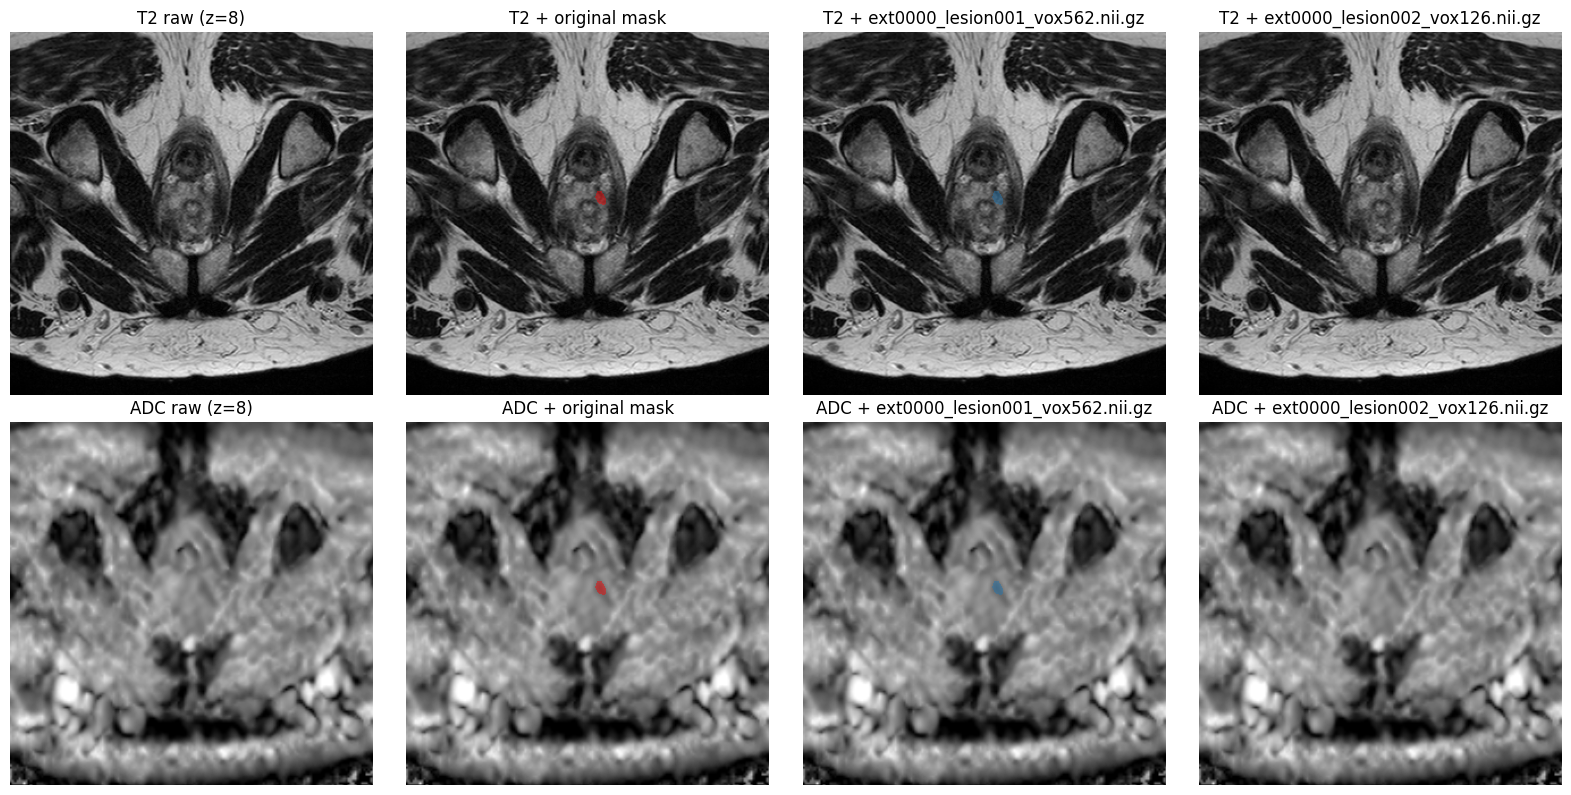

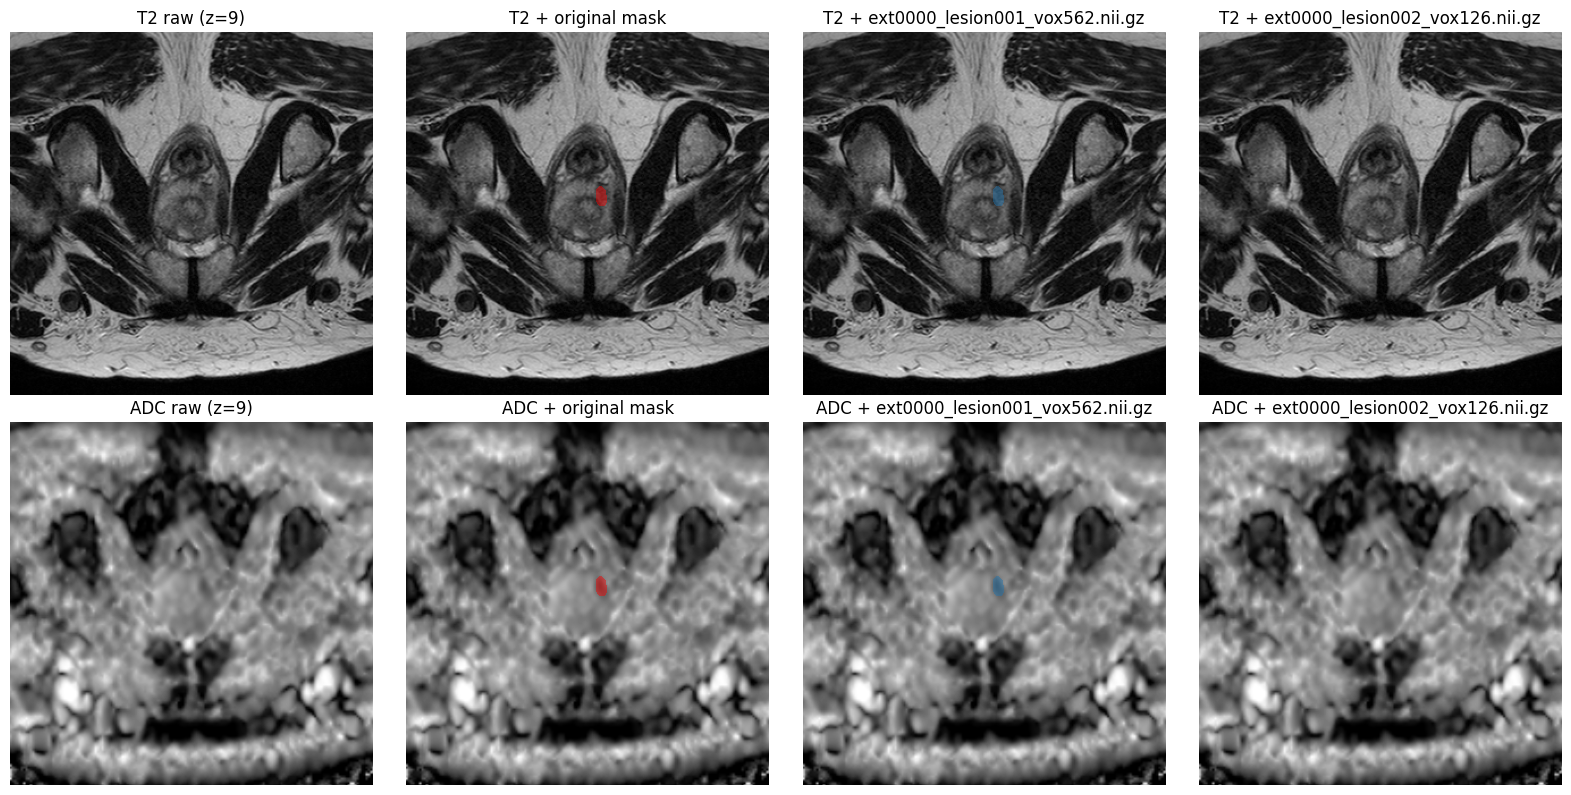

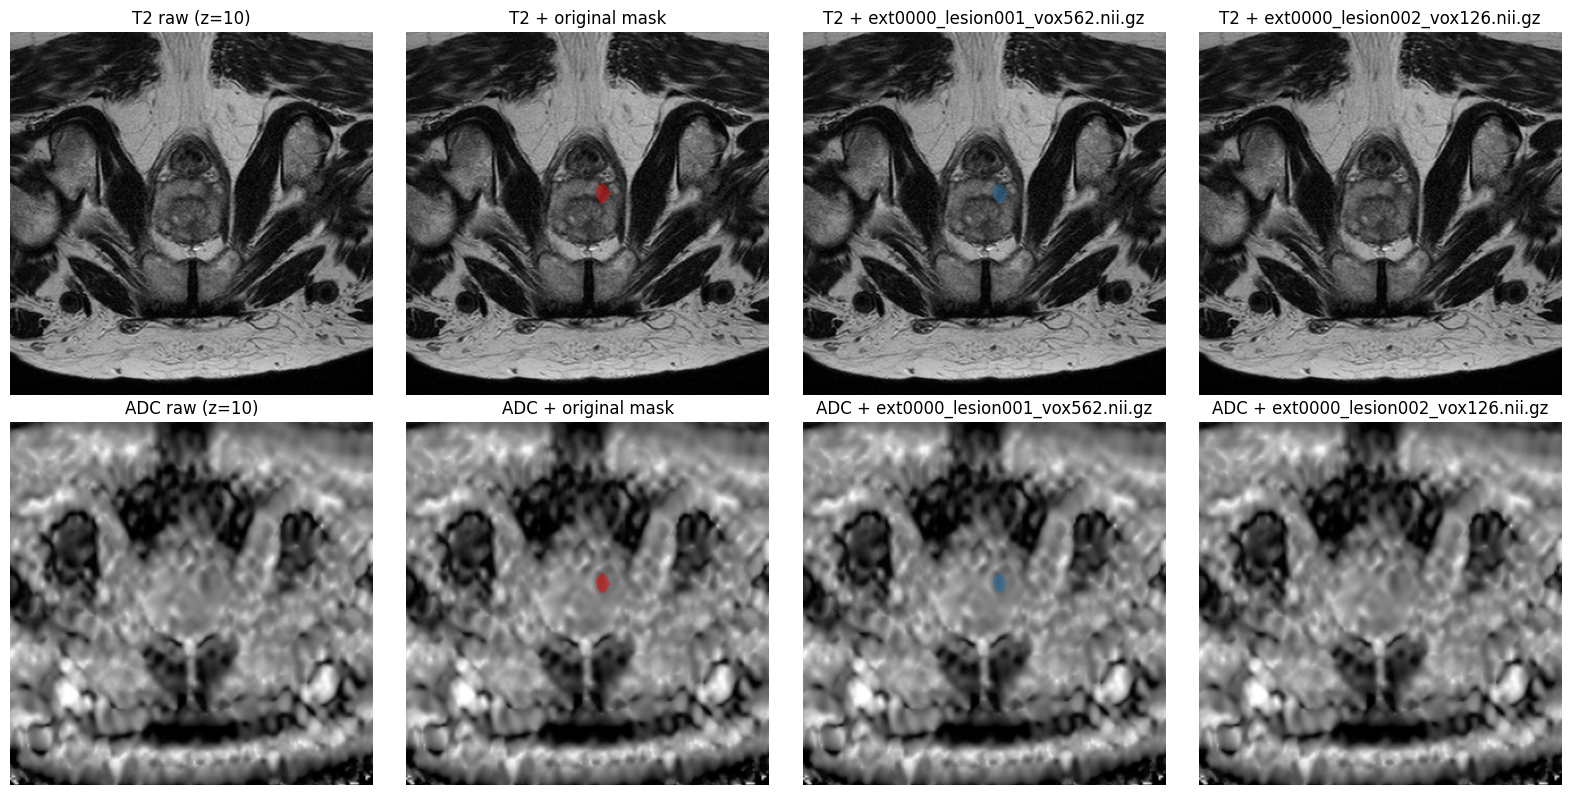

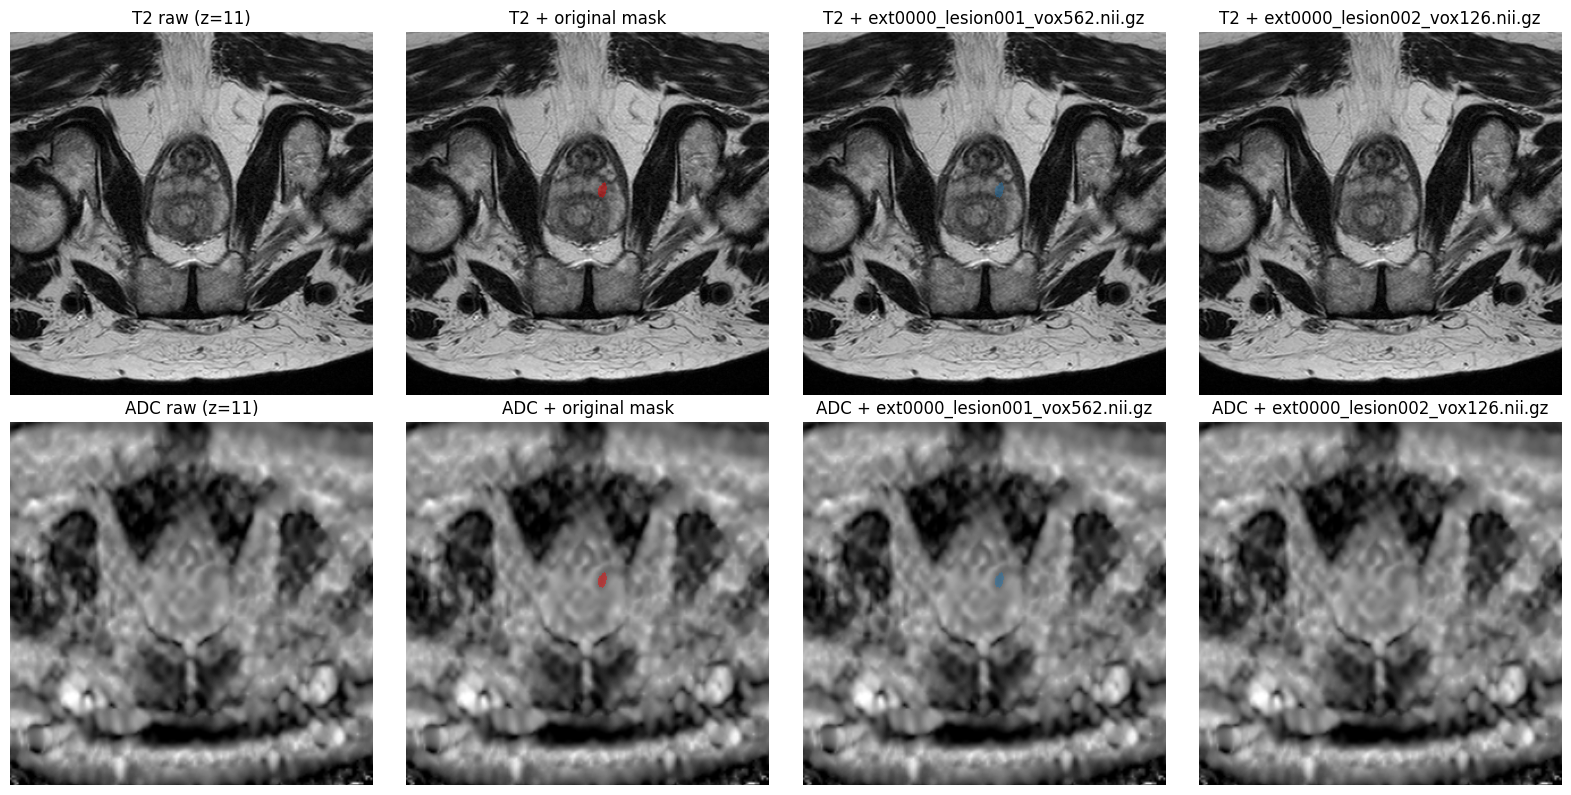

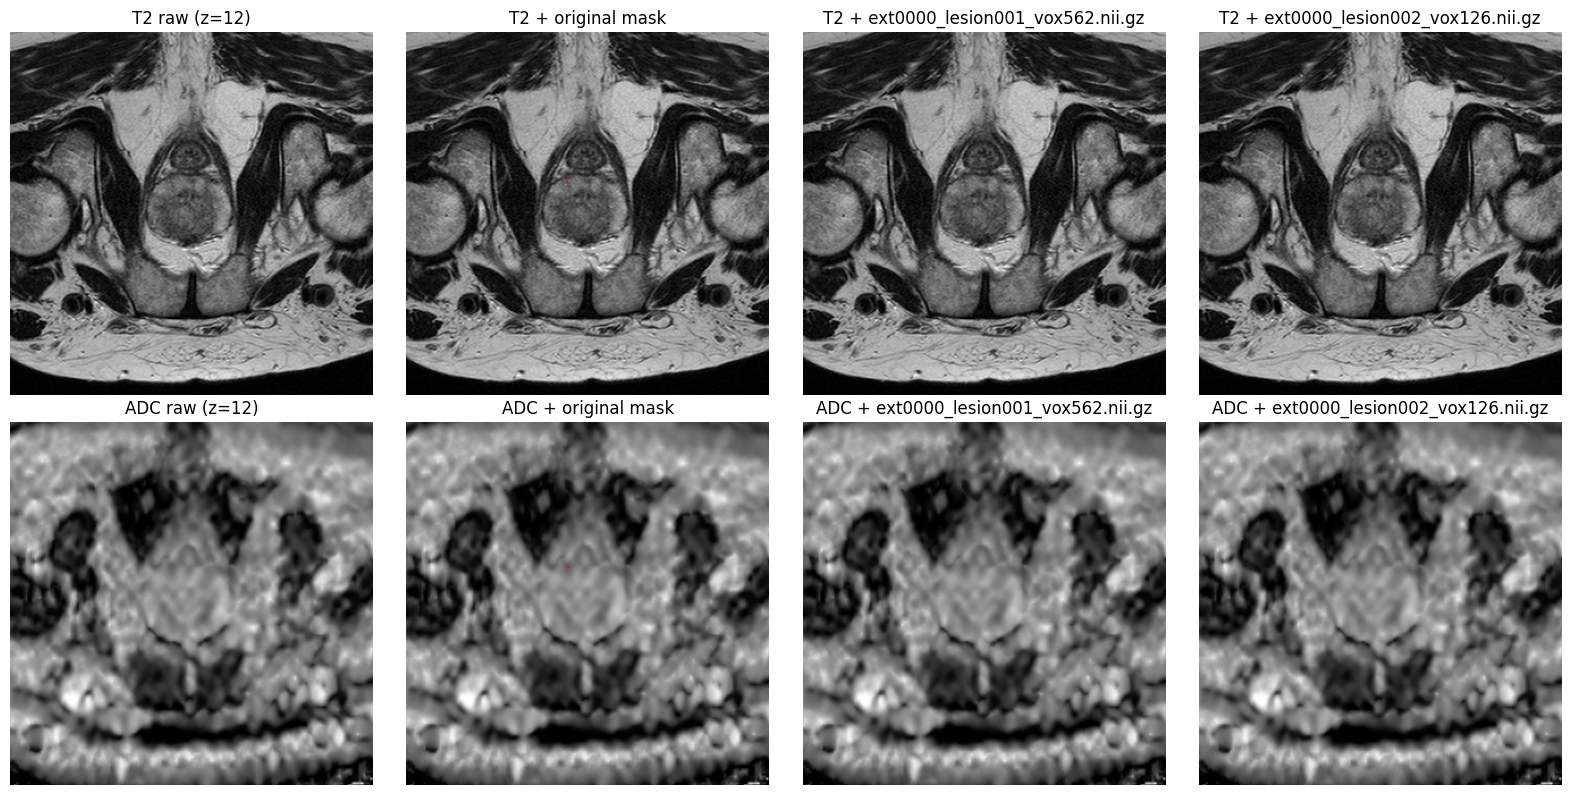

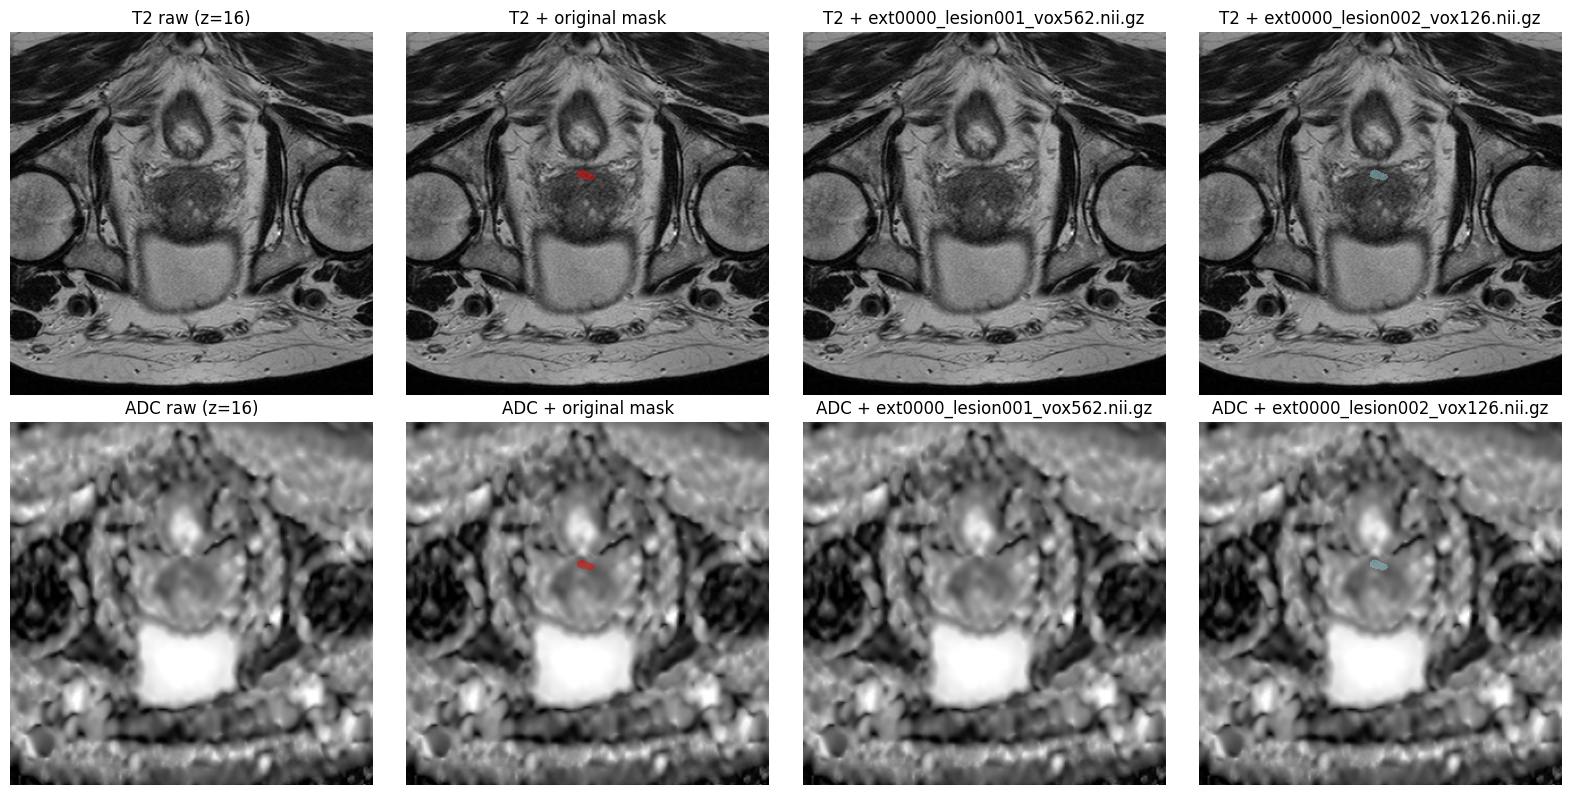

In [9]:
%matplotlib inline
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors

pred_path = OUTPUT_DIR / f"{CASE_ID}.nii.gz"
if not pred_path.exists():
    raise FileNotFoundError(f"Prediction not found: {pred_path}")

pred_vol = nib.load(str(pred_path)).get_fdata() > 0

img_adc = IMAGES_DIR / f"{CASE_ID}_0000.nii.gz"
img_t2 = IMAGES_DIR / f"{CASE_ID}_0001.nii.gz"
for p in [img_t2, img_adc]:
    if not p.exists():
        raise FileNotFoundError(f"Missing image: {p}")

t2_vol = nib.load(str(img_t2)).get_fdata()
adc_vol = nib.load(str(img_adc)).get_fdata()

if t2_vol.shape != pred_vol.shape or adc_vol.shape != pred_vol.shape:
    raise ValueError(
        f"Shape mismatch. pred={pred_vol.shape}, t2={t2_vol.shape}, adc={adc_vol.shape}"
    )

components_dir = OUTPUT_DIR / COMPONENTS_DIRNAME
component_files = sorted(components_dir.glob(f"{CASE_ID}_lesion*_vox*.nii.gz"))
comp_vols = [(p.name, nib.load(str(p)).get_fdata() > 0) for p in component_files]
component_colors = plt.cm.tab20(np.linspace(0, 1, max(len(comp_vols), 1)))

pred_per_slice = pred_vol.sum(axis=(0, 1))
lesion_slices = np.where(pred_per_slice > 0)[0].tolist()
if not lesion_slices:
    lesion_slices = [pred_vol.shape[2] // 2]
    print("No lesion voxels in prediction. Showing central slice:", lesion_slices[0])
else:
    print(f"Plotting {len(lesion_slices)} lesion-containing slice(s):", lesion_slices)

max_components_to_plot = len(comp_vols)
ncols = 2 + max_components_to_plot

for z in lesion_slices:
    fig, axes = plt.subplots(2, ncols, figsize=(4.0 * ncols, 8.0), squeeze=False)
    modalities = [("T2", t2_vol), ("ADC", adc_vol)]

    for r, (mod_name, vol) in enumerate(modalities):
        base_img = vol[:, :, z].T

        ax = axes[r, 0]
        ax.imshow(base_img, cmap="gray", origin="lower")
        ax.set_title(f"{mod_name} raw (z={z})")
        ax.axis("off")

        ax = axes[r, 1]
        ax.imshow(base_img, cmap="gray", origin="lower")
        pred2d = pred_vol[:, :, z].T.astype(float)
        pred2d[pred2d == 0] = np.nan
        ax.imshow(pred2d, cmap="autumn", alpha=0.45, origin="lower")
        ax.set_title(f"{mod_name} + original mask")
        ax.axis("off")

        for c, (comp_name, comp_vol) in enumerate(comp_vols, start=2):
            ax = axes[r, c]
            ax.imshow(base_img, cmap="gray", origin="lower")
            comp2d = comp_vol[:, :, z].T.astype(float)
            comp2d[comp2d == 0] = np.nan
            color = component_colors[c - 2]
            ax.imshow(comp2d, cmap=mcolors.ListedColormap([color]), alpha=0.45, origin="lower")
            ax.set_title(f"{mod_name} + {comp_name}")
            ax.axis("off")

    plt.tight_layout()
    plt.show()